<img src='./img/cng_thrivegeo_banner.png' class="center" width=95%>

# 🚀 Discover Cloud-Optimised GeoTIFFs (COGs)

## Introduction

A single Sentinel-2 band can be hundreds of megabytes, yet you often only need a small area, or a quick low-resolution preview. With a traditional GeoTIFF, you would have to download the whole file first.

A **C**loud-**O**ptimised **G**eoTIFF (COG) solves this. It is still a regular GeoTIFF, so any software that reads GeoTIFFs can read it. However, its contents are arranged so that you can fetch **only the parts you need** via HTTP range requests. Three features make this possible:

* 📋 **Header first**: the metadata sits at the start of the file, so one small request tells you the size, resolution and layout of the image.
* 🧩 **Tiles**: the image is split into square blocks (e.g. 1024 × 1024 pixels), so you can read just the tiles that cover your area of interest.
* 🔍 **Overviews**: lower-resolution copies of the image are stored inside the same file, so you can load a preview without reading every pixel.

In the previous notebook, you found Sentinel-2 scenes over **Snowbird, Utah**. Many of the assets you found are COGs. Now, you'll open them with `rasterio` and `rioxarray`, and read only the tiles and the resolution you need. Along the way, you'll keep track of how much of each file you actually download.

**Prerequisites:** basic Python and the *Discover STAC* notebook.

### By the end of this tutorial, you will be able to...

* ✅ **Check** whether a file is a valid COG with `cog_validate`
* 📋 **Read** a COG's metadata (resolution, tile size, overviews) with `rasterio`, without loading any pixels
* 🔍 **Load** only the resolution you need by choosing an overview level with `rioxarray`
* ✂️ **Clip** a COG to an area of interest, mask unwanted pixels and calculate NDVI

### Notebook Outline

* [Example 1️⃣: Find the COGs in a STAC Item](#title1)
* [Example 2️⃣: Look before you load](#title2)
* [Example 3️⃣: Tiles and overviews](#title3)
* [Exercise 1️⃣: Do the other bands fit?](#title4)
* [Example 4️⃣: Clip, mask and calculate NDVI](#title5)
* [Takeaways](#title6)

<hr>

**Import required libraries**

In [1]:
from pystac_client import Client
from pystac import  MediaType
import requests
import math
import rioxarray
import numpy as np
import rasterio
from rio_cogeo.cogeo import cog_validate
from rasterio.crs import CRS
from rasterio.warp import transform_bounds

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from shapely.geometry import box, shape
from matplotlib.patches import Rectangle

**Import helper functions**

In [2]:
from cng_workshop_aux import (
    cog_tiles_overview,
    metadata_cog
)

<hr>

<a id="title1"></a>

## Example 1️⃣ : Find the COGs in a STAC Item

In the *Discover STAC* notebook, you searched the [Earth Search](https://element84.com/earth-search/) catalog for Sentinel-2 scenes over Snowbird. Run that search again, but now for November 2025: **Sentinel-2 L2A**, **November 2025**, at most **30 % cloud cover**.

In [3]:
element84_catalog = Client.open("https://earth-search.aws.element84.com/v1/")

snowbird_bbox = (-111.724091, 40.517975, -111.493378, 40.640530)  # west, south, east, north
november_2025 = "2025-11-01/2025-11-30"

snowbird_clear = element84_catalog.search(
    collections="sentinel-2-l2a",
    datetime=november_2025,
    bbox=snowbird_bbox,
    query={"eo:cloud_cover": {"lte": 30}},
).item_collection()

print("Items with ≤ 30% clouds:", len(snowbird_clear))

Items with ≤ 30% clouds: 12


Snowbird lies close to the edge of a Sentinel-2 scene, so some of these Items cover only part of your area. Keep the ones that cover all of it, and list them with their date and cloud cover:

In [4]:
aoi = box(*snowbird_bbox)
covering = [scene for scene in snowbird_clear if shape(scene.geometry).contains(aoi)]

for scene in covering:
    print(scene.id, scene.datetime.date(), f"{scene.properties['eo:cloud_cover']:.1f}% cloud")

S2B_12TVK_20251127_0_L2A 2025-11-27 3.1% cloud
S2C_12TVK_20251122_0_L2A 2025-11-22 2.4% cloud
S2C_12TVK_20251102_0_L2A 2025-11-02 0.0% cloud


For now, take the scene with the least cloud:

In [5]:
 # min() returns the scene with the smallest cloud cover
item = min(covering, key=lambda scene: scene.properties["eo:cloud_cover"])

print("Your scene:", item.id)

Your scene: S2C_12TVK_20251102_0_L2A


You already know that the files of an Item are its **assets**, and that each asset has a media type. Use the media type to mark the COGs:

In [6]:
for key, asset in item.assets.items():
    is_cog = asset.media_type == MediaType.COG
    print(f"{key:20} {'COG' if is_cog else '   '}   {asset.title}")

aot                  COG   Aerosol optical thickness (AOT)
blue                 COG   Blue - 10m
cloud                      Cloud Probabilities
coastal              COG   Coastal - 60m
granule_metadata           None
green                COG   Green - 10m
nir                  COG   NIR 1 - 10m
nir08                COG   NIR 2 - 20m
nir09                COG   NIR 3 - 60m
product_metadata           None
red                  COG   Red - 10m
rededge1             COG   Red Edge 1 - 20m
rededge2             COG   Red Edge 2 - 20m
rededge3             COG   Red Edge 3 - 20m
scl                  COG   Scene classification map (SCL)
snow                       Snow Probabilities
swir16               COG   SWIR 1.6μm - 20m
swir22               COG   SWIR 2.2μm - 20m
tileinfo_metadata          None
visual               COG   True color image
wvp                  COG   Water Vapour (WVP)
thumbnail                  Thumbnail of preview image
aot-jp2                    Aerosol optical thickness (AOT)

::: {.callout-tip}
## Reflection and answers 

- ➡️ 1. Which assets are **not** COGs? What do you think they are used for?<br>
   ✏️ : The thumbnail (a JPEG) and the metadata files (XML and JSON) preview or describe the scene, but don't hold the measurements. The `-jp2` assets are the same bands in JPEG 2000, a format that isn't cloud-optimised. `cloud` and `snow` are extra probability layers, and they aren't marked as COGs either.
- ➡️ 2. Look at the asset titles. Do all bands have the same resolution?<br>
   ✏️ : No. `red`, `green`, `blue` and `nir` are 10 m, while `nir08`, the SWIR bands and `scl` are 20 m. You will need this in Exercise 1.
   
:::

::: {.callout-note}
## Note

Earth Search stores **each Sentinel-2 band as its own COG file**. That's why the Item has one asset per band (`red`, `nir08`, …), plus a few extra files such as a thumbnail and metadata.

Other providers put several bands into one multi-band COG. In that case, you'd see a single data asset. The asset list always tells you which layout you have.
:::

Each asset gives you two things you'll use in this notebook. The first is its `href`, the link to the file. It's all you need to open the COG:

In [7]:
red_href = item.assets["red"].href
red_href

'https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/12/T/VK/2025/11/S2C_12TVK_20251102_0_L2A/B04.tif'

The second is a short description of the pixel values, stored under `raster:bands`:

In [8]:
item.assets["red"].extra_fields["raster:bands"]

[{'nodata': 0,
  'data_type': 'uint16',
  'spatial_resolution': 10,
  'scale': 0.0001,
  'offset': -0.1}]

The values in the file are whole numbers, which saves space. `scale` and `offset` tell you how to turn them into real reflectance:<br>
`reflectance = value × scale + offset`

You don't need this yet. Keep it in mind for Example 4, where you calculate with the values.
You now know which files you need, and you have the link to the first one. Nothing has been downloaded so far. In Example 2, you'll find out what is inside the red band file before you load a single pixel.

<hr>

<a id="title2"></a>

## Example 2️⃣: Look before you load

You have the link to the red band. Before you download any pixels, you can learn more details about the data file. In this example, you ask four questions, and none of them needs the image itself:

1. ⚖️ **How big** is the file?
2. ✅ **Is it really** a COG?
3. 📋 **What does the header say?** The header is the "contents page" of the file.
4. 🧮 **What does that mean** for resolutions and tiles?


### ⚖️ Step 1: How big is the file?

You can ask the server for the size of a file without downloading it:

In [10]:
file_size_mb = int(requests.head(red_href).headers["Content-Length"]) / 1e6
print(f"File size: {file_size_mb:.0f} MB")

File size: 229 MB


This is what you'd have to download if the file were an ordinary GeoTIFF. Keep the number in mind: for the rest of the notebook, you'll compare what you actually read against it.

### ✅ Step 2: Is it really a COG?

A file can end in `.tif` without being cloud-optimised. `cog_validate()` checks the layout inside the file and returns three things:

* `True` or `False`: is the file a valid COG?
* a list of **errors**: problems that stop it from being a COG
* a list of **warnings**: things that work, but aren't ideal

In [11]:
is_valid, errors, warnings = cog_validate(red_href)

print("Valid COG:", is_valid)
print("Errors:   ", errors)
print("Warnings: ", warnings)

Valid COG: True
Errors:    []
Warnings:  []


::: {.callout-note}
## Note

**What if a file isn't a valid COG?**

You can still open it, but you lose the benefits. If it has no tiles or no overviews, or if its header sits at the end, your software may have to download most of the file to read even a small part.
:::


### 📋 Step 3: Read the header

Now open the file with `rasterio`. This reads **only the header**, a few kilobytes at the start of the file. No pixels are downloaded:

In [18]:
cog_red = rasterio.open(
    red_href
)

print(f"Size:            {cog_red.width} x {cog_red.height} pixels")
print(f"Resolution:      {cog_red.res[0]:.0f} m")
print(f"CRS:             {cog_red.crs}")
print(f"Tile size:       {cog_red.block_shapes[0][1]} x {cog_red.block_shapes[0][0]} pixels")
print(f"Overviews:       {cog_red.overviews(1)}")

Size:            10980 x 10980 pixels
Resolution:      10 m
CRS:             EPSG:32612
Tile size:       1024 x 1024 pixels
Overviews:       [2, 4, 8, 16]


Each line tells you something you'll use later:

<center>

| Line | Meaning |
|---|---|
| **Size** | The full image in pixels. One Sentinel-2 scene covers about 110 × 110 km. |
| **Resolution** | The size of one pixel on the ground. |
| **CRS** | The coordinate reference system. `EPSG:32612` is UTM zone 12N, so coordinates are in **metres**, not degrees. |
| **Tile size** | The image is cut into blocks of this size. Your software downloads whole tiles, never single pixels. |
| **Overviews** | The lower-resolution copies inside the file. The numbers are **reduction factors**: `2` means every 2 × 2 pixels are combined into one. |

</center>

### 🧮 Step 4: Do the sums

Two short calculations turn the header into something you can plan with.

**Overviews** 

In [13]:
for level, factor in enumerate(cog_red.overviews(1)):
    print(f"overview_level={level}:  {factor}x smaller  →  {cog_red.res[0] * factor:.0f} m")

overview_level=0:  2x smaller  →  20 m
overview_level=1:  4x smaller  →  40 m
overview_level=2:  8x smaller  →  80 m
overview_level=3:  16x smaller  →  160 m


**Tiles** 

In [14]:
tiles_across = math.ceil(cog_red.width / cog_red.block_shapes[0][1])
tiles_down = math.ceil(cog_red.height / cog_red.block_shapes[0][0])

print(f"{tiles_across} x {tiles_down} = {tiles_across * tiles_down} tiles at full resolution")

11 x 11 = 121 tiles at full resolution


::: {.callout-tip}
## Reflection and answers 

Look at the **Size** and **Tile size** above.

- ➡️ How many tiles does the whole image have? <br>
    ✏️ : 10,980 ÷ 1,024 ≈ 10.7, so you need **11 tiles** across and 11 down, which gives **121 tiles** in total. The last row and column are only partly filled.

:::


You've now met all three COG features from the introduction: the **header** came first, and it told you about the **tiles** and the **overviews**. So far, you've read only a few kilobytes of the file you loaded in Step 1.

<hr>

<a id="title3"></a>

## Example 3️⃣: Tiles and overviews



A Sentinel-2 scene covers about 110 × 110 km. Snowbird covers about 20 × 14 km of it. So how much of the file do you actually need? You'll answer that in two steps:

1. 🧩 **Where:** which tiles cover Snowbird?
2. 🔍 **How much detail:** how large do your pixels need to be?


### 🧩 Step 1:Which tiles cover Snowbird?

The header told you that the image is cut into 121 tiles. Now see where Snowbird falls in that grid. In the following you will create a plot, which shows:

* 🟥 **red lines** are the tile boundaries
* 🟦 the **blue square** is the first tile stored in the file (top left)
* 🟨 the **yellow box** is Snowbird

You can open the red band with overview level 0, which equals a resolution of 20m.

In [9]:
red_hr = rioxarray.open_rasterio(red_href, overview_level = 0)
red_hr

<xarray.DataArray (band: 1, y: 5490, x: 5490)> Size: 60MB
[30140100 values with dtype=uint16]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 44kB 4.5e+06 4.5e+06 4.5e+06 ... 4.39e+06 4.39e+06
  * x            (x) float64 44kB 4e+05 4e+05 4e+05 ... 5.097e+05 5.098e+05
    spatial_ref  int64 8B 0
Attributes:
    OVR_RESAMPLING_ALG:  AVERAGE
    AREA_OR_POINT:       Area
    _FillValue:          0
    scale_factor:        1.0
    add_offset:          0.0

The COG uses UTM coordinates in **metres**, and your Snowbird box is in **degrees**. The helper converts the box before drawing it.

In [16]:
# Reprojecting the AOI bbox:
sb_bbox_p = transform_bounds(CRS.from_epsg(4326), cog_red.crs, *snowbird_bbox)

And now, you can plot it.

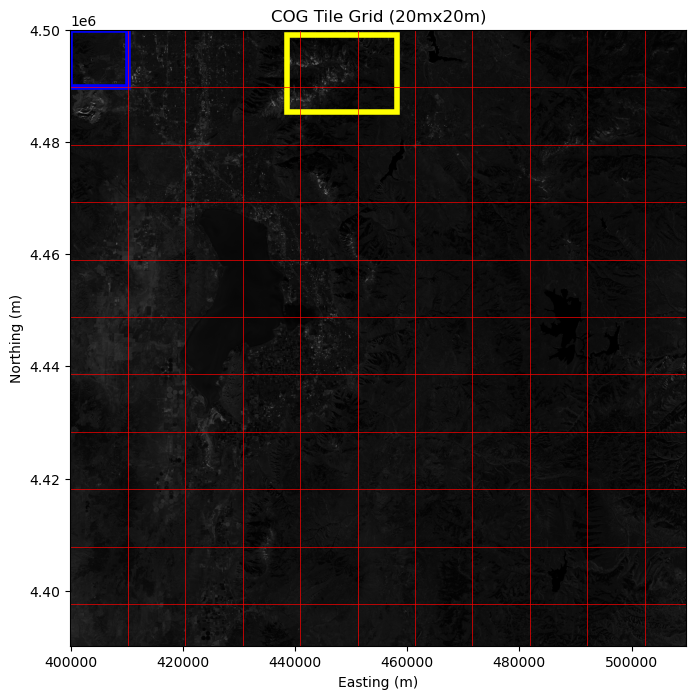

In [17]:
snow_bird = Rectangle(
    (sb_bbox_p[0],sb_bbox_p[1]),
    abs(sb_bbox_p[0]-sb_bbox_p[2]),abs(sb_bbox_p[1]-sb_bbox_p[3]),
    linewidth=4,
    edgecolor="yellow",
    facecolor="none",
)

#generating our resolutions grid coordinates:
x_coords = list(range(int(cog_red.bounds.left), int(cog_red.bounds.right), int((cog_red.block_shapes[0][0]*cog_red.res[0]))))
y_coords = list(range(int(cog_red.bounds.top), int(cog_red.bounds.bottom), -int((cog_red.block_shapes[0][1]*cog_red.res[1]))))

# Highlighting the first tile (top-left)
first_tile_xmin = cog_red.bounds.left
first_tile_xmax = cog_red.bounds.left + (cog_red.block_shapes[0][0]*cog_red.res[0])
first_tile_ymax = cog_red.bounds.top
first_tile_ymin = cog_red.bounds.top - ((cog_red.block_shapes[0][1]*cog_red.res[1]))

rect = Rectangle(
    (first_tile_xmin, first_tile_ymin),
    (cog_red.block_shapes[0][0]*cog_red.res[0]),
    (cog_red.block_shapes[0][1]*cog_red.res[1]),
    linewidth=4,
    edgecolor="blue",
    facecolor="none",
)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(red_hr.isel(band=0).values, cmap="gray", extent=[cog_red.bounds.left, cog_red.bounds.right, cog_red.bounds.bottom, cog_red.bounds.top])
ax.set_title("COG Tile Grid (20mx20m)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
# Add grid lines
for x in x_coords:
    ax.axvline(x=x, color="red", linewidth=0.5)
for y in y_coords:
    ax.axhline(y=y, color="red", linewidth=0.5)
ax.add_patch(rect)
ax.add_patch(snow_bird)

plt.show()

Going forward, you can now use the helper function `cog_tiles_overview` to make the same type of plots.

In [ ]:
# # You can also just run the following line of code.
 
#high_res = cog_tiles_overview(red_fr , cog_red , snowbird_bbox , None)

::: {.callout-tip}
## Reflection and answers

- ➡️ 1. How many tiles does the yellow box touch?<br>
    ✏️ : The yellow box touches **6 tiles**: three across and two down.
- ➡️ 2. The whole image has 121 tiles. Roughly what share of the file do you need for Snowbird?<br>
    ✏️ : That's about **5 %** of the image. Your software downloads just these tiles and skips the rest. This is the **tiles** feature at work.

Notice that the box sits right at the top edge of the scene. This is why some Items in Example 1 covered only part of your area.
:::

### 🔍 Step 2: Do you really need the full resolution?

Tiles let you skip the **parts** of the image you don't need. Overviews let you skip the **detail** you don't need. You want to know how green the valley is as a whole, not to pick out single trees, so 40 m pixels will do.

In Example 2, you listed the overview levels: `overview_level=1` gives you 40 m.


::: {.callout-note}
## Note

The levels count the **overviews**, starting at 0. So `overview_level=0` is the first overview, not the full-resolution image.

<center>

| You write | You get |
|---|---|
| *(leave `overview_level` out)* | 10 m, full resolution |
| `overview_level=0` | 20 m, the first overview |
| `overview_level=1` | 40 m, the second overview |
</center>
:::

Open the red band at 40 m with `rioxarray`. Just like `rasterio.open()`, this is **lazy**: you get an `xarray.DataArray` that knows the shape and the coordinates of the image, but no pixel values have been downloaded. Pixels are only fetched when you plot or calculate something.

In [10]:
red_lr = rioxarray.open_rasterio(red_href, overview_level = 1)
red_lr

<xarray.DataArray (band: 1, y: 2745, x: 2745)> Size: 15MB
[7535025 values with dtype=uint16]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 22kB 4.5e+06 4.5e+06 4.5e+06 ... 4.39e+06 4.39e+06
  * x            (x) float64 22kB 4e+05 4e+05 4.001e+05 ... 5.097e+05 5.097e+05
    spatial_ref  int64 8B 0
Attributes:
    OVR_RESAMPLING_ALG:  AVERAGE
    AREA_OR_POINT:       Area
    _FillValue:          0
    scale_factor:        1.0
    add_offset:          0.0

The array has 2,745 × 2,745 pixels. That's 4 times fewer in each direction than the full image, so 16 times fewer in total. Now see what this does to the tiles:

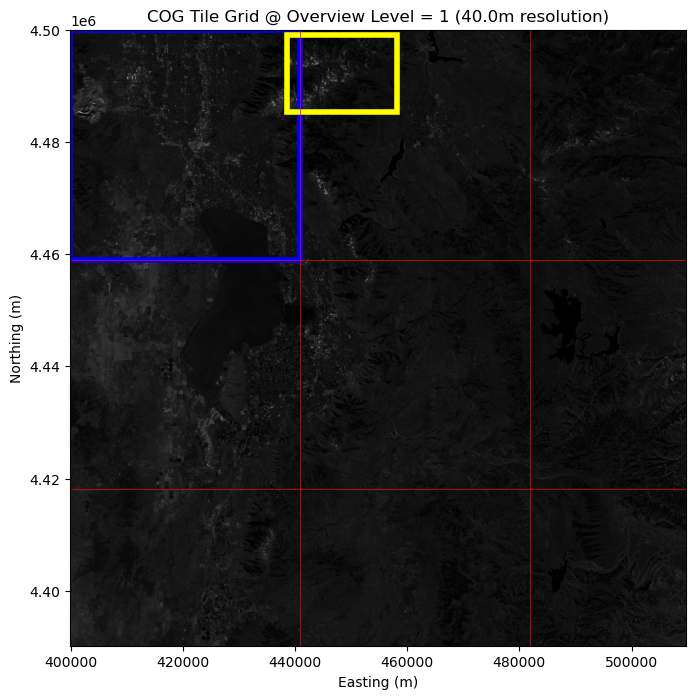

In [19]:
medium_res = cog_tiles_overview(red_lr, cog_red, snowbird_bbox, 1)

::: {.callout-tip}
## Reflection and answers 

- ➡️ 1. How many tiles does the whole image have at this overview level?<br>
    ✏️ : 3 × 3 = **9 tiles**. The image is now 2,745 pixels wide, and 2,745 ÷ 1,024 ≈ 2.7.
- ➡️ 2. How many tiles does the yellow box touch now?<br>
    ✏️ : The yellow box touches **2 tiles**. Each tile now covers about 41 × 41 km on the ground.
:::

<hr>

<a id="title4"></a>

## Exercise 1️⃣ : Do the other bands fit?

One band isn't enough to measure how green the valley is. In the next section, you'll calculate the **NDVI**, a measure of how green the vegetation is. For that, you need three bands of the same scene:

* 🔴 **`red`**: the red band, which you already have at 40 m as `red_lr`
* 🟤 **`nir08`**: near-infrared light, which healthy plants reflect strongly
* 🗺️ **`scl`**: the *Scene Classification Layer*, a map that gives every pixel a class number, such as vegetation, snow or cloud

You can only combine bands pixel by pixel if their pixels line up, so all three must have **the same resolution**. In Example 1, you saw that Sentinel-2 bands don't all have the same resolution. So before you combine anything, check.

::: {.callout-warning icon=false}
## Instructions

Open the other two bands so that they match `red_lr`:

- ➡️ 1. Open the headers of the `nir08` and `scl` assets with `rasterio`. Call them `cog_nir` and `cog_scl`, and print each one with the helper function `metadata_cog()`.<br>
- ➡️ 2. Fill in the table. Which `overview_level` gives you 40 m for each band?<br>
- ➡️ 3. Open both bands at 40 m with `rioxarray`. Call them `nir_band` and `scl_band`.

<center>

| Band | Full resolution | `overview_level` for 40 m |
|---|---|---|
| `red` | 10 m | 1 |
| `nir08` | _ | _ |
| `scl` | _ | _ |

</center>

**Hints**

- The link to a band is its `href`, e.g. `item.assets["nir08"].href`.
- `metadata_cog()` takes the `rasterio` object from step 1. It prints the same summary you made by hand in Example 2.
- Look at the note in Example 3 again: `overview_level=0` is the first overview, not the full resolution.
- Step 3 works just like `red_lr` in Example 3.

:::

Open the headers of the two new bands and print them. As before, this downloads no pixels:

In [11]:
cog_nir = rasterio.open(item.assets["nir08"].href)
cog_scl = rasterio.open(item.assets["scl"].href)

And for exploring metadata, you can use the function `metadata_cog`.

In [12]:
metadata_cog(cog_nir)

Size:          5490 x 5490 pixelsResolution:    20 m
CRS:           EPSG:32612
Tile size:     512 x 512 pixels
Overviews:     [2, 4, 8, 16]
The Resolution
per overview is: [40, 80, 160, 320] m


In [13]:
metadata_cog(cog_scl)

Size:          5490 x 5490 pixelsResolution:    20 m
CRS:           EPSG:32612
Tile size:     512 x 512 pixels
Overviews:     [2, 4, 8, 16]
The Resolution
per overview is: [40, 80, 160, 320] m


Both are 20 m bands, so their **first** overview is already 40 m. Hence, the same level number means a different resolution in different bands: `overview_level=0` is 20 m for `red`, but 40 m for `nir08`. That's why you need to check the header of every band you open.

::: {.callout-important}
## ✅ Checkpoint

Run the next cell, even if you solved the exercise yourself. It makes sure that everyone continues with the same three bands.
:::

In [16]:
red_band = red_lr   # opened at 40 m in Example 3
nir_band = rioxarray.open_rasterio(item.assets["nir08"].href, overview_level=0)
scl_band = rioxarray.open_rasterio(item.assets["scl"].href, overview_level=0)

print("red: ", red_band.shape)
print("nir: ", nir_band.shape)
print("scl: ", scl_band.shape)

red:  (1, 2745, 2745)
nir:  (1, 2745, 2745)
scl:  (1, 2745, 2745)


<hr>

<a id="title5"></a>

## Example 4️⃣ : Clip, mask and calculate NDVI

You have three bands that line up: `red_band`, `nir_band` and `scl_band`, all at 40 m. They still cover the whole 110 km scene, and nothing has been downloaded yet. In this example, you turn them into a vegetation map of Snowbird in four steps:

1. ✂️ **Clip** the bands to Snowbird
2. 🗺️ **Look** at what is in the scene
3. 🎭 **Prepare** the values: convert them to reflectance, and mask the pixels you don't need
4. 🧮 **Calculate** the NDVI and plot it

### ✂️ Step 1: Clip to Snowbird

Clipping tells `xarray` which part of the image you want. Because the arrays are still lazy, this also decides **which tiles will be downloaded**: only those that touch Snowbird, just as you counted in Example 3.

The COG uses coordinates in metres, so first convert your Snowbird box from degrees. Then keep only the pixels inside it with `.sel()`. Note that `y` runs **from north to south**, because images are stored from the top row down. So the `y` slice starts at `north`.

In [19]:
west, south, east, north = transform_bounds("EPSG:4326", cog_red.crs, *snowbird_bbox)

red_band = red_band.sel(x=slice(west, east), y=slice(north, south))
nir_band = nir_band.sel(x=slice(west, east), y=slice(north, south))
scl_band = scl_band.sel(x=slice(west, east), y=slice(north, south))

red_band

<xarray.DataArray (band: 1, y: 344, x: 490)> Size: 337kB
[168560 values with dtype=uint16]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 3kB 4.499e+06 4.499e+06 ... 4.485e+06 4.485e+06
  * x            (x) float64 4kB 4.387e+05 4.387e+05 ... 4.582e+05 4.583e+05
    spatial_ref  int64 8B 0
Attributes:
    OVR_RESAMPLING_ALG:  AVERAGE
    AREA_OR_POINT:       Area
    _FillValue:          0
    scale_factor:        1.0
    add_offset:          0.0

Each band now has 344 × 490 pixels. That's about 170,000 pixels, compared with 7.5 million in the whole 40 m image.

### 🗺️ Step 2: Look at what is in the scene

Before you remove any pixels, look at what is there. The **Scene Classification Layer (SCL)** gives every pixel a class number:

<center>

| Class | Meaning | Keep for NDVI? |
|---|---|---|
| 4 | Vegetation | ✅ |
| 5 | Not vegetated (bare soil, rock, buildings) | ✅ |
| 3 | Cloud shadow | ❌ |
| 6 | Water | ❌ |
| 8, 9, 10 | Clouds and thin cirrus | ❌ |
| 11 | Snow and ice | ❌ |
| 0 | No data | ❌ |

</center>

NDVI describes plants and bare ground. Over clouds, shadows, water and snow, it tells you nothing about vegetation, so you'll keep only classes **4** and **5**.

The following code draws the classes. This is the first time you download pixels: the SCL tiles over Snowbird.

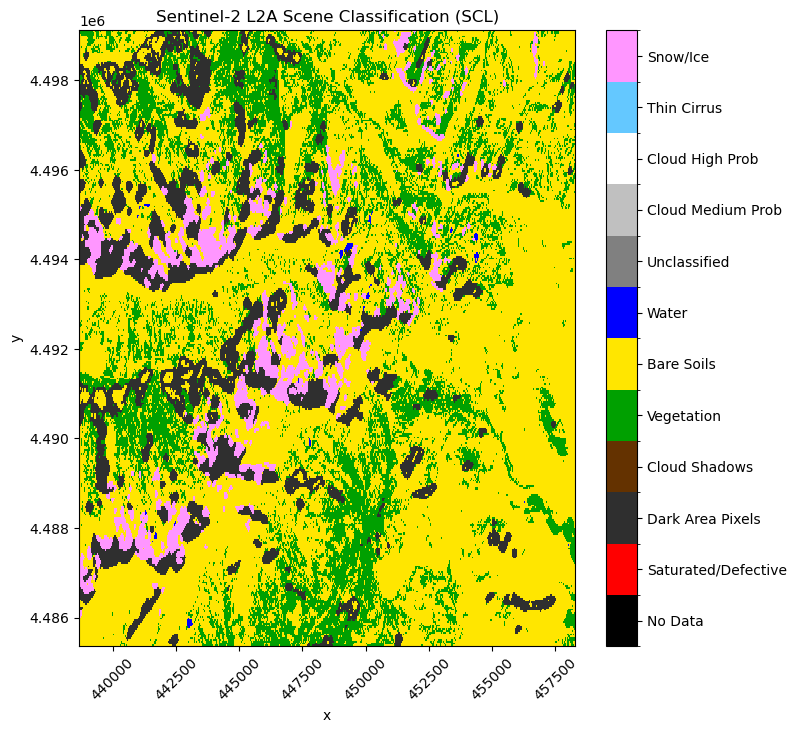

In [20]:
# Define standard ESA color mapping for Sentinel-2 SCL (values 0 through 11)
scl_colors = {
    0:  ('#000000', 'No Data'),
    1:  ('#ff0000', 'Saturated/Defective'),
    2:  ('#2f2f2f', 'Dark Area Pixels'),
    3:  ('#643200', 'Cloud Shadows'),
    4:  ('#00a000', 'Vegetation'),
    5:  ('#ffe600', 'Bare Soils'),
    6:  ('#0000ff', 'Water'),
    7:  ('#808080', 'Unclassified'),
    8:  ('#c0c0c0', 'Cloud Medium Prob'),
    9:  ('#ffffff', 'Cloud High Prob'),
    10: ('#64c8ff', 'Thin Cirrus'),
    11: ('#ff96ff', 'Snow/Ice')
}

# Extract colors and labels
hex_colors = [scl_colors[i][0] for i in range(12)]
labels = [scl_colors[i][1] for i in range(12)]

cmap_scl = ListedColormap(hex_colors)
norm = BoundaryNorm(np.arange(-0.5, 12.5, 1), cmap_scl.N)

# Plot SCL Data
fig, ax = plt.subplots(figsize=(8, 8))
im = scl_band.plot(
    ax=ax,
    cmap=cmap_scl,
    norm=norm,
    add_colorbar=False
)

# Custom categorical colorbar legend
cbar = fig.colorbar(im, ticks=np.arange(0, 12))
cbar.ax.set_yticklabels(labels)

plt.title('Sentinel-2 L2A Scene Classification (SCL)')
plt.xlabel('x')
plt.ylabel('y')
plt.tick_params(axis='x', labelrotation=45)
plt.grid(False)
plt.axis('tight')

plt.show()

::: {.callout-tip}
## Reflection and answers 

- ➡️ 1. Which class covers most of the valley?<br>
    ✏️ : The legend lists every class in the scene with its share of the pixels. The largest share is the class that covers most of the valley.
- ➡️ 2. You'll keep only classes 4 and 5. Which classes will be removed, and what share of the area is that? Is there any snow yet?<br>
    ✏️ : Everything except classes 4 and 5 will be removed. Add up their shares in the legend. If "Snow or ice" is in the list, winter has started to arrive, and those pixels will be removed too.
:::

### 🎭 Step 3: Prepare the values

There are two things to do before you calculate.

**Convert to reflectance.** In Example 1, you saw that the files store whole numbers, and that `scale` and `offset` turn them into real reflectance. Do that now for both bands:

In [21]:
def to_reflectance(band, asset_key):
    info = item.assets[asset_key].extra_fields["raster:bands"][0]
    return band * info["scale"] + info["offset"]

red = to_reflectance(red_band, "red")
nir = to_reflectance(nir_band, "nir08")

This is the moment the red and near-infrared pixels are downloaded: `rioxarray` fetches them as soon as you calculate with them. It fetches only the tiles over Snowbird, at 40 m.

**Mask.** Keep only vegetation (4) and not-vegetated ground (5). `isin([4, 5])` creates a True/False map. `where()` keeps the pixels where the map is `True`, and replaces all others with `NaN` ("not a number", i.e. no value):

In [22]:
keep = scl_band.isin([4, 5])

red = red.where(keep)
nir = nir.where(keep)

print(f"Pixels kept: {float(keep.mean()):.0%}")

Pixels kept: 82%


In [23]:
red_band.isnull().mean()

<xarray.DataArray ()> Size: 8B
array(0.)
Coordinates:
    spatial_ref  int64 8B 0
Attributes:
    OVR_RESAMPLING_ALG:  AVERAGE
    AREA_OR_POINT:       Area
    _FillValue:          0
    scale_factor:        1.0
    add_offset:          0.0

### 🧮 Step 4: Calculate the NDVI

The **Normalised Difference Vegetation Index (NDVI)** compares near-infrared and red light. Healthy plants reflect a lot of near-infrared light and absorb red light, so the difference between the two tells you how green an area is:

`NDVI = (NIR - Red)/(NIR + Red)`


* 🌲 **above about 0.3**: vegetation, and the higher the value, the greener
* 🪨 **around 0 to 0.2**: bare soil, rock or buildings
* 💧 **0 or below**: water, snow and clouds, which you have masked out

Because the bands are `xarray` arrays, you can write the formula almost exactly as it looks on paper:

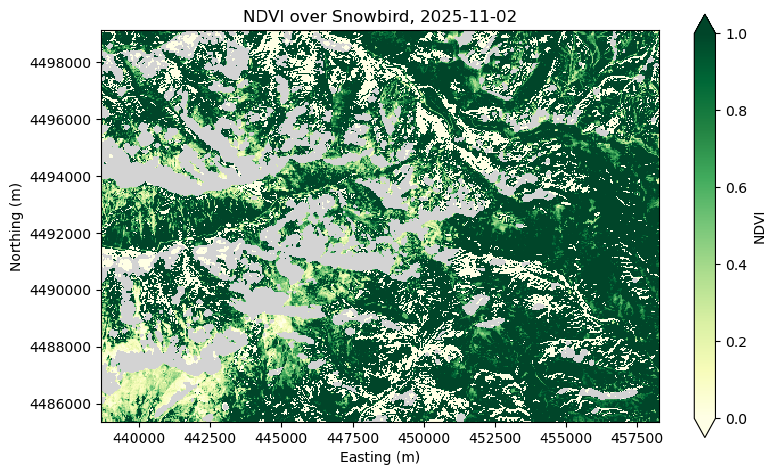

In [24]:
ndvi = (nir - red) / (nir + red)

ndvi.plot(cmap="YlGn", vmin=0, vmax=1, figsize=(9, 5.5), cbar_kwargs={"label": "NDVI"})
plt.title(f"NDVI over Snowbird, {item.datetime.date()}")
plt.gca().set_facecolor("lightgrey")   # masked pixels show as grey
plt.gca().set_aspect("equal")
plt.ticklabel_format(style="plain")
plt.xlabel("Easting (m)")
plt.ylabel("Northing (m)")
plt.show()

::: {.callout-note}
## Note

**Why convert to reflectance first?**

Take a pixel with the stored values 1,300 (red) and 3,500 (near-infrared). With the raw numbers, the NDVI would be 0.46. With real reflectance (0.03 and 0.25), it is 0.79. The offset doesn't cancel out in the formula, so skipping this step gives you the wrong answer without any error message.
:::

::: {.callout-tip}
## Reflection and answers 

- ➡️ 1. Look at the values in `red_band`. What has replaced the masked pixels?<br>
    ✏️ : The highest values are on the forested slopes, where evergreen trees stay green. The lowest are on the bare, rocky peaks and in built-up areas.
- ➡️ 2. What share of the pixels did you remove? Check with `red_band.isnull().mean()`. Does this match what you saw in the SCL plot?<br>
    ✏️ : The grey areas are the pixels you masked out. They match the classes you removed in the SCL plot.
    
:::

<hr>

<a id="title6"></a>

## Takeaways

In this notebook, you opened satellite images stored as **Cloud-Optimised GeoTIFFs** and read only the parts you needed: first the metadata, then a lower-resolution overview, and finally just the pixels over your area of interest.

**What you learned**

* ✅ **Validate:** `cog_validate(href)` tells you whether a file is a proper COG.
* 📋 **Inspect before loading:** `rasterio.open(href)` reads only the header. From it you get the resolution, tile size, CRS and the list of overviews, all without downloading any pixels.
* 🔍 **Choose your resolution:** `rioxarray.open_rasterio(href, overview_level=n)` loads a lower-resolution copy stored inside the same file. Fewer pixels means fewer tiles to fetch.
* ✂️ **Clip, mask and calculate:** `.sel(x=slice(...), y=slice(...))` keeps only your area of interest. `.isin()` and `.where()` apply a quality mask, and band arithmetic gives you indices such as NDVI.


**Things to keep in mind**

* Bands in the same product can have different resolutions (e.g. 10 m for red, 20 m for NIR), so pick overviews that match before combining them.
* `overview_level=0` is the **first overview**, not the full-resolution image. Leave the argument out to get full resolution.
* Tile size and the number of overviews differ between providers, so always check the metadata first.
* `rioxarray` loads data lazily. Pixels are only fetched when you compute or plot.

**Next steps**

COGs are ideal for 2D images. The next notebook introduces **Zarr**, a cloud-native format for large multidimensional arrays.

📚 *Further reading:* [cogeo.org](https://cogeo.org) · [rioxarray docs](https://corteva.github.io/rioxarray) · [stackstac docs](https://stackstac.readthedocs.io) · [Cloud-Optimized Geospatial Formats Guide](https://guide.cloudnativegeo.org)

<hr>

&copy; 2026 thriveGEO GmbH
